![Banner](../images/03_02_banner_spatial_analysis_DTM.png)

# Hydrology Modeling 

Hydrology modeling is a key aspect of understanding how water moves across landscapes. Using digital elevation models (DEMs), we can analyze surface water processes such as flow routing, watershed delineation, and stream extraction. This notebook demonstrates how to perform hydrological analysis in Python with GeoLattice, leveraging its `spatial_analysis.surface_hydrology` module for comprehensive and efficient workflows. The methods covered here can help identify water accumulation patterns, drainage networks, and catchment areas, essential for environmental studies, water management, and risk assessment.


## Overview

Spatial hydrology analyses how water moves and accumulates across a land surface
using a digital elevation model (DEM). It is one of the deepest specialisations
in Whitebox-style terrain analysis and spans DEM conditioning, flow routing,
watershed delineation, stream extraction, and connectivity / storage modelling.

This notebook uses `geolattice.spatial_analysis.surface_hydrology` with the **entire**
Bangladesh hilly-district DEM (`Data/00_shared/raster_data/Bangladesh/hilly_dem_BTM.tiff`,
Bangladesh Transverse Mercator, 250 m; ~521 × 1329 cells). The workflow follows
the topics in the
[Whitebox Workflows Spatial Hydrology chapter](https://www.whiteboxgeo.com/manuals/api/python/spatial-hydrology.html)
and the R notes in `R_Code/surface-hydrological-anlysis-whitbox-r.qmd`.

| Stage | Tools | Role |
|---|---|---|
| DEM conditioning | `breach_depressions`, `fill_depressions` | Remove sinks so flow can drain |
| Flow direction | D8, Rho8, Dinf, FD8, MDinf, Quinn, minimal dispersion | Encode where water goes |
| Flow accumulation | D8 cells, Dinf specific contributing area | Upslope area / SCA |
| Streams | `extract_streams`, segmentation | Threshold the channel network |
| Watersheds | `watershed`, `subbasins`, `basins` | Upslope catchments |
| Indices | TWI, elevation above stream, distance to stream | Wetness / floodplain proxies |
| Advanced | stochastic depressions, connectivity, impoundment | Uncertainty and storage |

Outputs are written under `Data/00_shared/raster_data/output_folder/bangladesh/hydrology`.


## API overview (`surface_hydrology`)

```
- breach_depressions / fill_depressions
- d8_pointer, rho8_pointer, dinf_pointer
- fd8_pointer, mdinf_pointer, quinn_pointer, minimal_dispersion_pointer
- d8_flow_accumulation, dinf_flow_accumulation
- extract_streams, stream_segmentation, catchment_delineation
- snap_pour_points, watershed, subbasins, basins
- wetness_index (TWI), elevation_above_stream, downslope_distance_to_stream
- stochastic_depression_analysis, hydrologic_connectivity, impoundment_analysis
```


## Core concepts

### The hydrologic DEM problem

Most raw DEMs contain **surface depressions**: cells or groups of cells enclosed
by higher neighbours. They may be real topographic basins, acquisition noise, or
interpolation artefacts. Standard single-flow routing (D8) cannot route water out
of closed sinks: the algorithm terminates where no downhill neighbour exists.

Before flow routing, the DEM must be **conditioned** so spurious depressions are
removed while genuine basins (lakes, wetlands) can be preserved when desired.

Two principal strategies:

1. **Filling**: raise cells inside each depression up to the spill (pour-point)
   elevation. Guarantees a drained surface but can create large flats that need a
   secondary gradient (flat increment).
2. **Breaching**:  cut a narrow least-cost channel through the barrier around a
   depression. Preserves more of the original elevation field and is preferred when
   barriers are road embankments or similar artefacts.

In practice a **hybrid** approach: breach where possible, fill remaining sinks,
is often optimal (Whitebox `breach_depressions_least_cost(..., fill_deps=True)`).

### Flow direction algorithms

After conditioning, a flow-direction raster encodes where water leaves each cell:

| Algorithm | Flow type | Best use |
|---|---|---|
| **D8** | Single (deterministic) | Channel delineation, simple watersheds |
| **Rho8** | Single (stochastic) | Reduces D8 cardinal bias |
| **D-infinity (Dinf)** | Multiple (proportional split) | Hillslope flux, dispersive flow |
| **FD8** | Multiple (proportional) | Shallow overland flow |
| **MD-infinity** | Multiple | Subsurface / soil-moisture modelling |
| **Quinn et al.** | Multiple (FD8 variant) | Wetness index, slope-area workflows |
| **Minimal dispersion** | Adaptive | Balance between D8 and Dinf |

See the [Whitebox Spatial Hydrology manual](https://www.whiteboxgeo.com/manuals/api/python/spatial-hydrology.html)
for the same taxonomy.


## Setup

Locate the repository root, import hydrology helpers, and create the output folder.

**Installation.** This notebook needs installation option 2 (core plus spatial analysis): `pip install "geolattice[analysis]"`. See "Installation options" in the GeoLattice README.

In [1]:
# Display matplotlib figures inline in this Jupyter notebook.
%matplotlib inline

from pathlib import Path  # filesystem paths for locating the DEM and outputs

# Third-party numeric / plotting stack used throughout the notebook.
import matplotlib.pyplot as plt  # figure and axes creation for hydrology maps
import numpy as np  # array ops for DEM differencing and stream masks
import pandas as pd  # tabular display of summarize_raster results
from IPython.display import display  # rich table previews in the notebook

# ===================================================================
# Setup and helpers for surface hydrology.
# Import GeoLattice hydrology helpers, point BD/OUT/DEM at sample paths, and define
# show_raster() for quick GeoTIFF summaries.
# ===================================================================

# The installed package lives in src/; the repository root is its parent.
import geolattice

ROOT = Path(geolattice.__file__).resolve().parents[1]
if not (ROOT / "Data").is_dir():
    raise FileNotFoundError("Could not find the GeoLattice repository root.")


# Raster I/O helpers used to inspect DEM and derivative rasters.
from geolattice.raster import (
    open_raster_data,  # open a GeoTIFF for metadata / arrays
    summarize_raster,  # count/min/max/mean/percentiles
)
# Surface hydrology helpers used in the exercises below.
from geolattice.spatial_analysis import (
    basins,  # whole-DEM basin IDs from a D8 pointer
    breach_depressions,  # carve outlets through depressions
    catchment_delineation,  # catchment from a pour point (available)
    d8_flow_accumulation,  # D8 upslope accumulation
    d8_pointer,  # D8 flow-direction pointer codes
    dinf_flow_accumulation,  # D-infinity specific catchment area
    dinf_pointer,  # D-infinity flow direction
    downslope_distance_to_stream,  # along-flow distance to channel
    elevation_above_stream,  # HAND-style height above nearest stream
    extract_streams,  # threshold flow accumulation to streams
    fd8_pointer,  # FD8 / MFD fractional outflow weights
    fill_depressions,  # raise sinks to create a hydrologic DEM
    hillshade,  # shaded relief for map context
    hydrologic_connectivity,  # connectivity to the stream network
    impoundment_analysis,  # dam / impoundment size index
    rho8_pointer,  # stochastic Rho8 pointer
    snap_pour_points,  # snap outlets onto nearby stream cells
    stochastic_depression_analysis,  # depression probability under DEM error
    stream_segmentation,  # assign unique IDs to stream links
    subbasins,  # subbasins for each stream link
    watershed,  # watersheds for a set of pour points
    wetness_index,  # topographic wetness index
)
from geolattice.viz import apply_map_style, plot_raster, plot_raster_histogram, plot_rasters  # map helpers

# Paths to the Bangladesh DEM and a dedicated hydrology output folder.
BD = ROOT / "Data" / "00_shared" / "raster_data" / "Bangladesh"  # Bangladesh raster samples
OUT = ROOT / "Data" / "00_shared" / "raster_data" / "output_folder" / "bangladesh" / "hydrology"  # write outputs here
OUT.mkdir(parents=True, exist_ok=True)  # create the output folder if needed
DEM = BD / "hilly_dem_BTM.tiff"  # 250 m BTM DEM for the hilly districts
assert DEM.exists(), f"Missing DEM: {DEM}"  # fail early if the DEM is absent

apply_map_style()  # apply the GeoLattice tutorial matplotlib map defaults


def show_raster(path, title=None):
    """Print a short metadata summary for a GeoTIFF."""
    path = Path(path)  # normalize to Path
    with open_raster_data(path) as ds:  # open for metadata only
        gt = ds.geotransform  # origin and pixel size
        print(f"path:    {path.name}")  # file name
        print(f"size:    {ds.width} x {ds.height}  bands={ds.band_count}")  # dimensions
        print(f"res:     {abs(gt[1]):.4f} x {abs(gt[5]):.4f}")  # pixel size
        print(f"bounds:  {ds.bounds}")  # geographic extent
        print(f"crs:     {ds.crs}")  # coordinate reference system
        print(f"nodata:  {ds.get_band(1).nodata}")  # nodata flag
        if title:
            print(f"title:   {title}")  # optional label


print(f"DEM:    {DEM}")  # confirm DEM path
print(f"Output: {OUT}")  # confirm output folder


DEM:    /home/zia207/Github/GeoLattice/Data/00_shared/raster_data/Bangladesh/hilly_dem_BTM.tiff
Output: /home/zia207/Github/GeoLattice/Data/00_shared/raster_data/output_folder/bangladesh/hydrology


## Data

30 m SRTM elevation resampled to **250 m** for the hilly districts of Bangladesh
(Bandarban / Chittagong Hill Tracts), projected to Bangladesh Transverse Mercator
(`hilly_dem_BTM.tiff`). The same DEM underpins the R Whitebox hydrology notes.


path:    hilly_dem_BTM.tiff
size:    521 x 1329  bands=1
res:     250.0000 x 250.0000
bounds:  Bounds(648050.3746814046, 295017.2625412984, 778300.3746814046, 627267.2625412983)
crs:     PROJCS["unknown",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",90],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",-2000000],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
nodata:  nan
title:   Hilly districts DEM (BTM)


,value
count,310665
min,-7.796429
max,985.049622
mean,109.007889
std,129.049986
sum,33864935.903503
percentiles,"{'p2': 3.0354053211212157, 'p25': 29.240074157..."


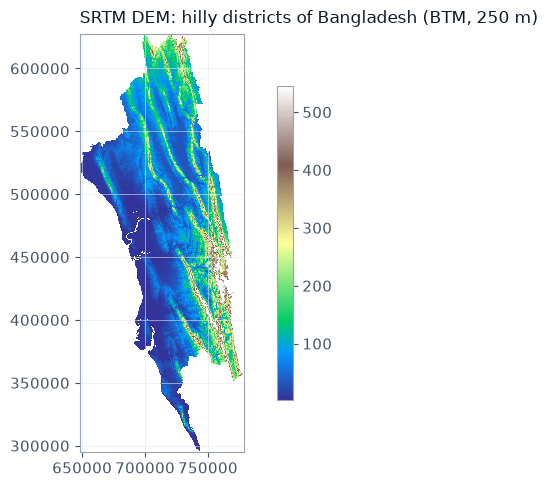

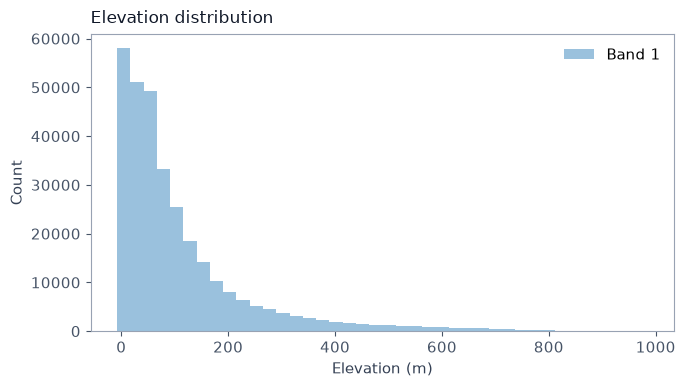

In [2]:
# Print DEM metadata and elevation summary statistics.
show_raster(DEM, "Hilly districts DEM (BTM)")  # path, size, CRS, nodata
stats = summarize_raster(DEM, percentiles=(2, 25, 50, 75, 98))  # robust percentiles
display(pd.Series(stats).to_frame("value"))  # show stats as a one-column table

# Terrain-colored map of the full Bangladesh hilly DEM.
ax = plot_raster(
    DEM,  # path to the elevation GeoTIFF
    title="SRTM DEM: hilly districts of Bangladesh (BTM, 250 m)",  # map title
    cmap="terrain",  # elevation-friendly colormap
    kind="general",  # single-band continuous display
    robust=True,  # percentile stretch for contrast
    show=False,  # defer display
)
plt.show()  # render the DEM map

# Elevation histogram for the same DEM.
ax = plot_raster_histogram(DEM, bins=40, title="Elevation distribution", show=False)
ax.set_xlabel("Elevation (m)")  # label the x-axis with elevation units
plt.show()  # render the histogram


## Hillshade

Shaded relief helps interpret flow pathways against topography. We compute
hillshade for the **full** DEM and use it as a backdrop in later maps.

All subsequent hydrology steps run on the entire
`hilly_dem_BTM.tiff` mosaic (no AOI clip).


path:    hilly_dem_BTM.tiff
size:    521 x 1329  bands=1
res:     250.0000 x 250.0000
bounds:  Bounds(648050.3746814046, 295017.2625412984, 778300.3746814046, 627267.2625412983)
crs:     PROJCS["unknown",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",90],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",-2000000],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
nodata:  nan
title:   Full DEM (BTM)


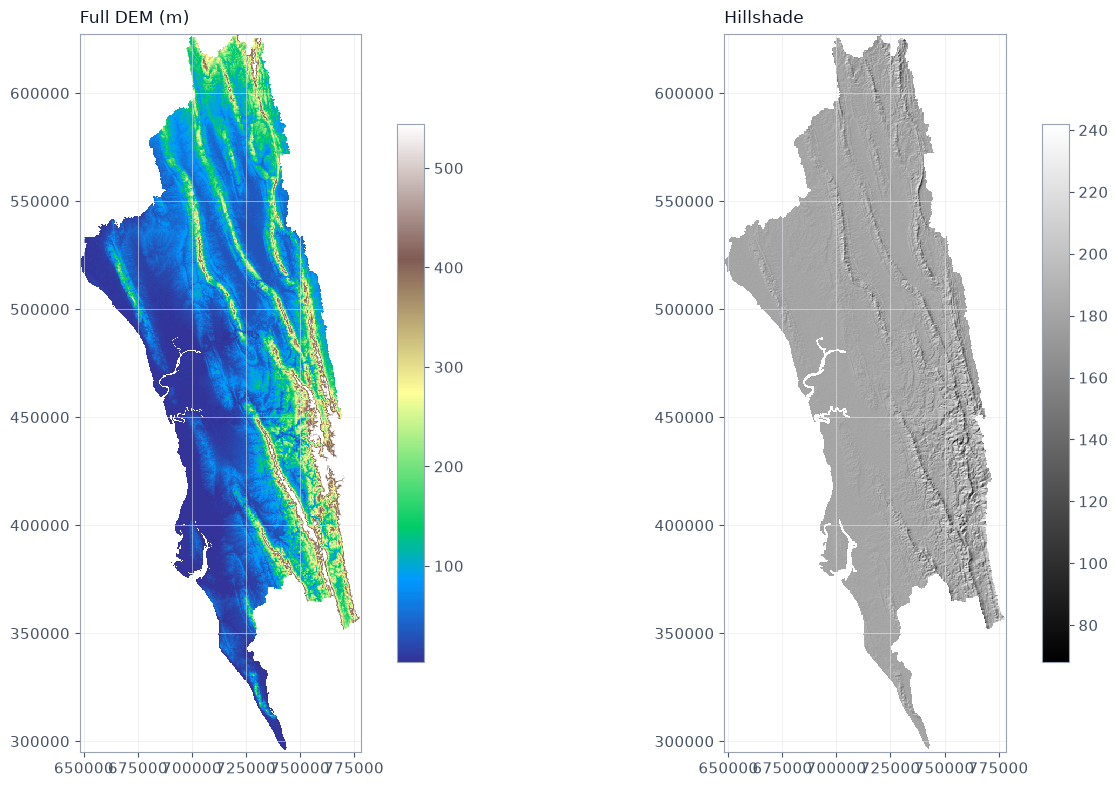

In [3]:
# Use the full Bangladesh hilly-district DEM for the hydrology workflow.
dem = DEM  # full Bangladesh hilly-district DEM
show_raster(dem, "Full DEM (BTM)")  # confirm extent and resolution

# Compute a single-direction hillshade for cartographic context under flow maps.
hs = OUT / "hillshade.tif"  # hillshade output path
hillshade(dem, hs, azimuth=315, altitude=45, overwrite=True)  # NW sun at 45 deg

# Side-by-side DEM and hillshade.
fig, axes = plt.subplots(1, 2, figsize=(14, 8))  # wide two-panel figure
plot_raster(dem, ax=axes[0], title="Full DEM (m)", cmap="terrain", robust=True, show=False)
plot_raster(hs, ax=axes[1], title="Hillshade", cmap="gray", show=False)
plt.tight_layout()  # reduce unused whitespace
plt.show()  # render both panels


## DEM conditioning

Hydrology tools route water downhill based on cell elevations. If no neighbour is
lower, flow stops: a **sink**, **pit**, or **depression**.

### Filling vs breaching

For a depression with pour-point elevation $z_p$ and interior cells $z_i$:

$$
z_i^{\text{filled}} = \max(z_i,\, z_p)
$$

Priority-flood / Wang-Liu filling raises every interior cell to $z_p$. Flats may
need a tiny gradient $\varepsilon$ so D8 has a unique direction:

$$
z^{\text{flat}} = z_p + k\,\varepsilon,\quad k = 0,1,2,\ldots
$$

**Breaching** instead lowers a path of cells through the barrier. A least-cost
breach minimises cumulative vertical cost subject to maximum length / depth
constraints (Whitebox `breach_depressions_least_cost`).

`geolattice` exposes:

- `breach_depressions`: single-cell pits + priority breach / optional fill
- `fill_depressions`: Wang-Liu-style priority flood with optional flat fix


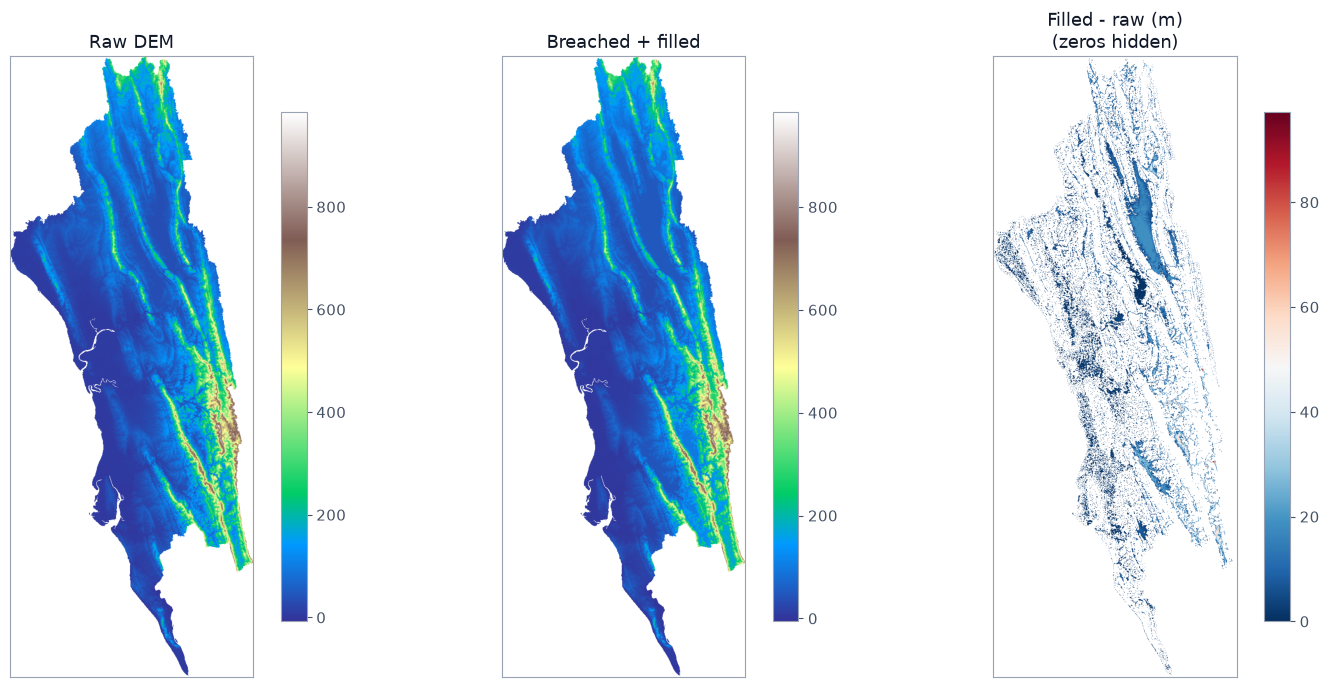

Cells raised by fill: 62779
Max fill depth (m):   97.249


In [4]:
# Condition the DEM: breach depressions, then fill remaining sinks.
breached = OUT / "dem_breached.tif"  # DEM after depression breaching
filled = OUT / "dem_filled.tif"  # hydrologically conditioned DEM

breach_depressions(dem, breached, fill_pits=True, overwrite=True)  # carve outlets through sinks
fill_depressions(breached, filled, fix_flats=True, overwrite=True)  # raise leftover sinks / flats

# Visualise how conditioning changed the DEM.
with open_raster_data(dem) as ds:
    z0 = np.asarray(ds.read(bands=1), dtype=np.float64)  # raw elevation array
    nd = ds.get_band(1).nodata  # nodata flag
if nd is not None:
    z0 = np.where(z0 == nd, np.nan, z0)  # mask nodata as NaN

with open_raster_data(filled) as ds:
    z1 = np.asarray(ds.read(bands=1), dtype=np.float64)  # filled elevation array
    nd = ds.get_band(1).nodata  # nodata flag
if nd is not None:
    z1 = np.where(z1 == nd, np.nan, z1)  # mask nodata as NaN

diff = z1 - z0  # fill depth (positive where fill raised the surface)
diff = np.where(np.abs(diff) < 1e-6, np.nan, diff)  # hide near-zero differences

# Three-panel comparison: raw, filled, and fill depth.
fig, axes = plt.subplots(1, 3, figsize=(16, 7))  # three-panel figure
im0 = axes[0].imshow(z0, cmap="terrain")  # raw DEM
axes[0].set_title("Raw DEM")  # left panel title
plt.colorbar(im0, ax=axes[0], fraction=0.046)  # colorbar for raw elevations
im1 = axes[1].imshow(z1, cmap="terrain")  # conditioned DEM
axes[1].set_title("Breached + filled")  # middle panel title
plt.colorbar(im1, ax=axes[1], fraction=0.046)  # colorbar for filled elevations
im2 = axes[2].imshow(diff, cmap="RdBu_r")  # fill depth
axes[2].set_title("Filled - raw (m)\n(zeros hidden)")  # right panel title
plt.colorbar(im2, ax=axes[2], fraction=0.046)  # colorbar for fill depth
for ax in axes:
    ax.set_xticks([])  # hide x tick labels
    ax.set_yticks([])  # hide y tick labels
plt.tight_layout()  # reduce unused whitespace
plt.show()  # render the comparison

print(f"Cells raised by fill: {int(np.nansum(diff > 0))}")  # count of filled cells
print(f"Max fill depth (m):   {float(np.nanmax(diff)) if np.isfinite(np.nanmax(diff)) else 0:.3f}")  # max fill


## Flow direction

### D8 (O'Callaghan & Mark, 1984)

Each cell $i$ sends all flow to the neighbour $j$ with the steepest drop:

$$
S_j = \frac{z_i - z_j}{d_{ij}},\qquad
d_{ij} = \begin{cases}
\Delta x & \text{cardinal}\\
\sqrt{2}\,\Delta x & \text{diagonal}
\end{cases}
$$

$$
\text{receiver}(i) = \arg\max_{j \in N_8(i)} S_j
$$

Whitebox / this package store the direction as a **pointer code** (power of 2):

| Code | 1 | 2 | 4 | 8 | 16 | 32 | 64 | 128 |
|---|---|---|---|---|---|---|---|---|
| Dir | E | SE | S | SW | W | NW | N | NE |

### Rho8 (Fairfield & Leymarie, 1991)

Same neighbourhood, but the receiver is drawn randomly with probability
proportional to $S_j$ among downslope neighbours: reducing D8's preference for
cardinal axes.

### D-infinity (Tarboton, 1997)

Flow is split between **two** adjacent downslope neighbours according to the
aspect angle of the steepest triangular facet. If the facet angle is $\alpha$
and the facet spans $0\ldots\alpha_{\max}$:

$$
p_{\text{card}} = 1 - \frac{\alpha}{\alpha_{\max}},\qquad
p_{\text{diag}} = \frac{\alpha}{\alpha_{\max}}
$$

The pointer raster stores continuous direction (degrees clockwise from east in
Whitebox style).

### FD8 / Quinn / MDinf / minimal dispersion

- **FD8 (Freeman)**: weights $\propto (S_j)^p$ to all downslope neighbours
  (default $p \approx 1.1$).
- **Quinn**: FD8 variant with contour-length factor: common in wetness work.
- **MD-infinity**: apportions flow among multiple triangular facets.
- **Minimal dispersion**: blends D8 (channels) and Dinf (hillslopes) using a
  local convergence proxy.


/tmp/geolattice-src-path/geolattice/spatial_analysis/surface_hydrology.py:1414: RuntimeWarning: invalid value encountered in power
  weights[i] = np.where(positive, (drop ** exp) * factor, 0.0)


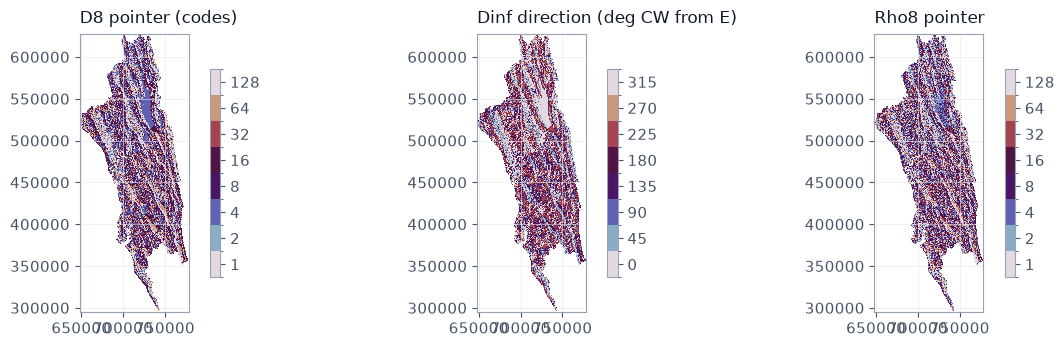

FD8 weight stack: 8 bands (fractional outflow to 8 neighbours)


In [5]:
# Compute D8, D-infinity, and Rho8 flow-direction pointers from the filled DEM.
d8p = OUT / "d8_pointer.tif"  # D8 pointer codes
dinf_p = OUT / "dinf_pointer.tif"  # D-infinity flow direction
rho8_p = OUT / "rho8_pointer.tif"  # stochastic Rho8 pointer

d8_pointer(filled, d8p, overwrite=True)  # single-receiver D8 codes
dinf_pointer(filled, dinf_p, overwrite=True)  # continuous D-infinity directions
rho8_pointer(filled, rho8_p, seed=42, overwrite=True)  # Rho8 with fixed seed

# Optional multi-band MFD weights (8 bands: E..NE).
fd8_p = OUT / "fd8_weights.tif"  # FD8 fractional outflow stack
fd8_pointer(filled, fd8_p, exponent=1.1, overwrite=True)  # MFD weights with slope exponent

# Map the three single-band pointer surfaces.
plot_rasters(
    [d8p, dinf_p, rho8_p],  # pointer paths
    titles=["D8 pointer (codes)", "Dinf direction (deg CW from E)", "Rho8 pointer"],  # panel titles
    ncols=3,  # three columns
    cmap="twilight",  # cyclic-friendly colormap
    robust=True,  # percentile stretch
    show=False,  # defer display
)
plt.show()  # render the pointer maps

with open_raster_data(fd8_p) as ds:
    print(f"FD8 weight stack: {ds.band_count} bands (fractional outflow to 8 neighbours)")  # confirm 8 bands


## Flow accumulation

Flow accumulation measures how much upslope area drains through each cell. It is
the primary surface for extracting streams, delineating watersheds, and building
wetness indices.

### D8 cell-count accumulation

Process cells from high to low elevation. Let $A_i$ be the accumulation at cell
$i$ (initialised to 1 = the cell itself):

$$
A_j \leftarrow A_j + A_i \quad\text{for receiver } j = \text{D8}(i)
$$

Optional output types:

| `out_type` | Formula | Units |
|---|---|---|
| `"cells"` | $A_i$ | cell count |
| `"area"` | $A_i \,(\Delta x)^2$ | m² |
| `"sca"` / `"catchment_area"` | $A_i \,\Delta x$ | m (specific catchment area) |

### Specific contributing area (D-infinity)

With Dinf proportional weights $w_{ij}$ to downslope neighbours:

$$
A_j \leftarrow A_j + w_{ij}\, A_i
$$

**Specific contributing area** (SCA) normalises by cell width and is the $a$
term in TWI and many erosion models
([Whitebox SCA section](https://www.whiteboxgeo.com/manuals/api/python/spatial-hydrology.html#specific-contributing-area-d-infinity)):

$$
\mathrm{SCA}_i = a_i = A_i^{\text{cells}} \cdot \Delta x
\quad [\mathrm{m}]
$$

Log-transforming $A$ or SCA helps visualisation because values span many orders
of magnitude.


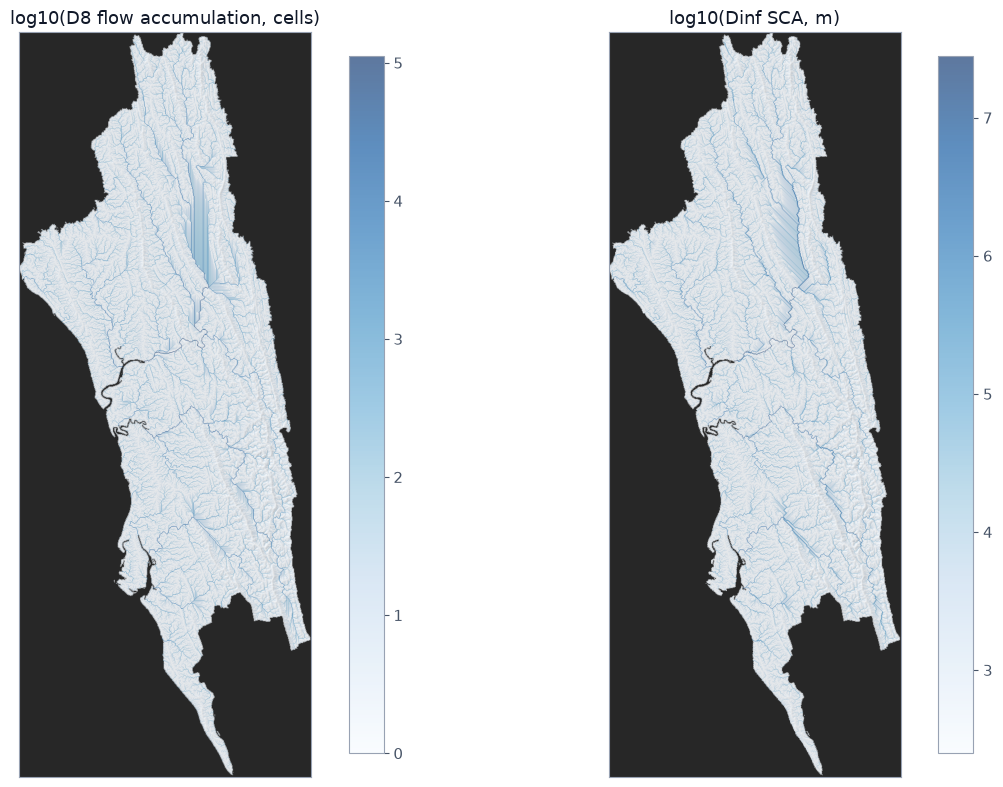

D8 FA  min/max cells: 1 / 111669
Dinf SCA min/max (m):   250.0 / 27919750.0


In [6]:
# Compute D8 cell accumulation and D-infinity specific catchment area (SCA).
fa_cells = OUT / "d8_flow_accum_cells.tif"  # D8 accumulation in cells
sca = OUT / "dinf_sca.tif"  # D-infinity SCA in metres

d8_flow_accumulation(filled, fa_cells, out_type="cells", overwrite=True)  # upslope cell count
dinf_flow_accumulation(filled, sca, out_type="sca", overwrite=True)  # specific catchment area

# Log-transform accumulation for display (span many orders of magnitude).
with open_raster_data(fa_cells) as ds:
    fa = np.asarray(ds.read(bands=1), dtype=np.float64)  # D8 accumulation array
    nd = ds.get_band(1).nodata  # nodata flag
    gt = ds.geotransform  # keep geotransform for later outlet placement
if nd is not None:
    fa = np.where(fa == nd, np.nan, fa)  # mask nodata
fa_log = np.log10(np.maximum(fa, 1.0))  # log10 for visualization

with open_raster_data(sca) as ds:
    sca_arr = np.asarray(ds.read(bands=1), dtype=np.float64)  # SCA array
    nd = ds.get_band(1).nodata  # nodata flag
if nd is not None:
    sca_arr = np.where(sca_arr == nd, np.nan, sca_arr)  # mask nodata
sca_log = np.log10(np.maximum(sca_arr, 1.0))  # log10 for visualization

with open_raster_data(hs) as ds:
    hs_arr = np.asarray(ds.read(bands=1), dtype=np.float64)  # hillshade backdrop

# Overlay log accumulation on hillshade.
fig, axes = plt.subplots(1, 2, figsize=(14, 8))  # two-panel figure
for ax, arr, title in zip(
    axes,
    [fa_log, sca_log],  # log-transformed surfaces
    ["log10(D8 flow accumulation, cells)", "log10(Dinf SCA, m)"],  # panel titles
):
    ax.imshow(hs_arr, cmap="gray", alpha=0.85)  # hillshade base
    im = ax.imshow(arr, cmap="Blues", alpha=0.65)  # accumulation overlay
    ax.set_title(title)  # panel title
    ax.set_xticks([])  # hide x ticks
    ax.set_yticks([])  # hide y ticks
    plt.colorbar(im, ax=ax, fraction=0.046)  # colorbar for log values
plt.tight_layout()  # reduce unused whitespace
plt.show()  # render both panels

print(f"D8 FA  min/max cells: {np.nanmin(fa):.0f} / {np.nanmax(fa):.0f}")  # D8 range
print(f"Dinf SCA min/max (m):   {np.nanmin(sca_arr):.1f} / {np.nanmax(sca_arr):.1f}")  # SCA range


## Topographic Wetness Index (TWI)

TWI is a terrain-based proxy for soil moisture and saturation potential
(Beven & Kirkby; Quinn et al.). Areas with **large upslope area** and **gentle
slopes** tend to stay wetter.

$$
\mathrm{TWI} = \ln\!\left(\frac{a}{\tan\beta}\right)
$$

where:

- $a$ = specific catchment area (m): preferably from **Dinf SCA**
- $\beta$ = local slope angle (radians)

Implementation notes:

- Clamp $\beta \ge \beta_{\min}$ (e.g. $0.001°$) to avoid $\tan\beta = 0$.
- Clamp $a \ge a_{\min}$ to avoid $\ln 0$.

`wetness_index(..., method="dinf"|"d8")` computes SCA and slope internally.
Higher TWI -> greater wetness / runoff-generation potential.


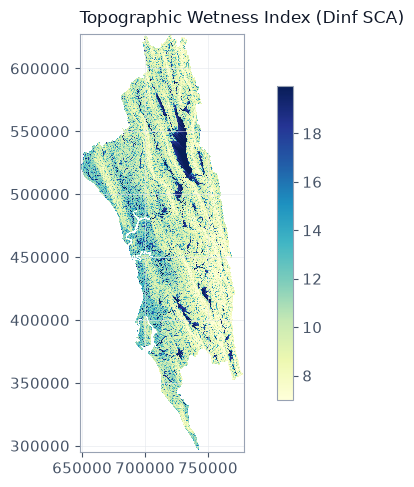

,TWI
count,303775
min,6.002364
max,28.062782
mean,10.831988
std,3.190679
sum,3290487.289107
percentiles,"{'p5': 7.3527120590209964, 'p25': 8.6701817512..."


In [7]:
# Compute Topographic Wetness Index from the filled DEM using D-infinity SCA.
twi_path = OUT / "twi.tif"  # TWI output path
wetness_index(filled, twi_path, method="dinf", overwrite=True)  # TWI = ln(a / tan(beta))

# Map TWI with a blue-green colormap.
ax = plot_raster(
    twi_path,  # TWI GeoTIFF
    title="Topographic Wetness Index (Dinf SCA)",  # map title
    cmap="YlGnBu",  # wetness-friendly colormap
    kind="general",  # single-band continuous display
    robust=True,  # percentile stretch
    show=False,  # defer display
)
plt.show()  # render the TWI map

stats = summarize_raster(twi_path, percentiles=(5, 25, 50, 75, 95))  # TWI percentiles
display(pd.Series(stats).to_frame("TWI"))  # show summary table


## Stream network extraction

Channel cells appear in the flow-accumulation surface as locations with very
large contributing area. A simple **threshold** maps the network:

$$
\text{stream}_i =
\begin{cases}
1 & A_i \ge T\\
0 & \text{otherwise}
\end{cases}
$$

$T$ depends on DEM resolution and landscape. For this full 250 m mosaic we use
a threshold of **1000 cells** (same order as the R Whitebox notes); lower it for
a denser network.

Downstream tools:

- `stream_segmentation`: unique IDs for links between junctions / heads / outlets
- `catchment_delineation` / `subbasins`: upslope area of each link

Whitebox also converts raster streams to vectors with a D8 pointer
(`raster_streams_to_vector`); here we stay in raster space for the notebook.


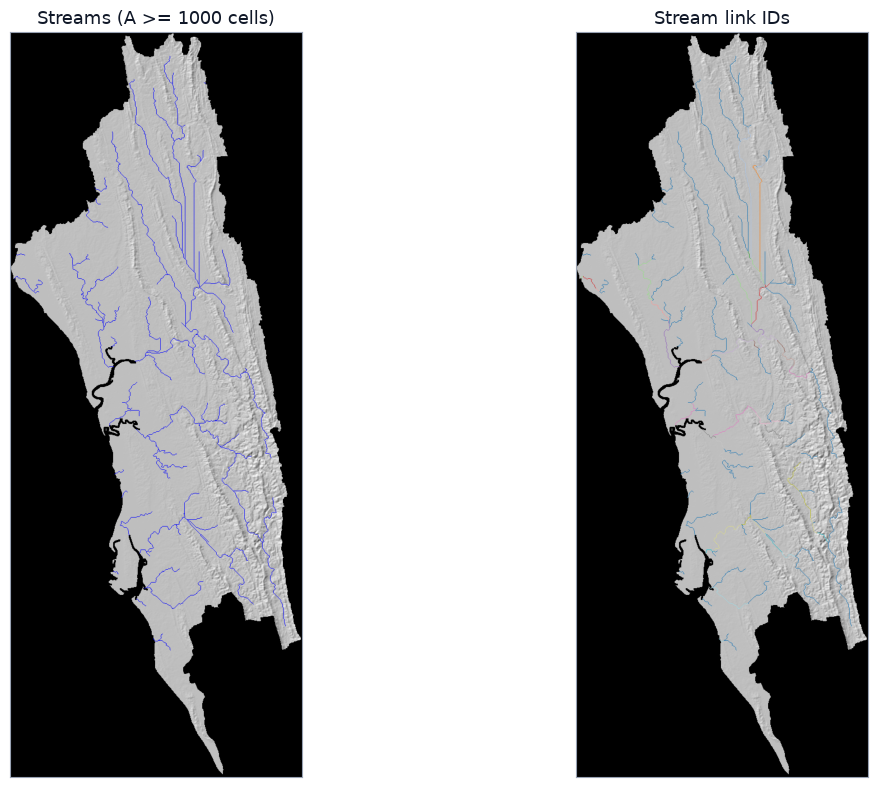

Stream cells: 5745
Unique links: 783


In [8]:
# Threshold in cells: tune to landscape / resolution (full DEM).
STREAM_THRESHOLD = 1000  # minimum upslope cells to classify as stream

streams = OUT / "streams.tif"  # binary stream raster
extract_streams(fa_cells, streams, threshold=STREAM_THRESHOLD, overwrite=True)  # threshold FA

links = OUT / "stream_links.tif"  # unique stream-link IDs
stream_segmentation(streams, d8p, links, overwrite=True)  # segment the network

# Read stream and link arrays for plotting.
with open_raster_data(streams) as ds:
    st = np.asarray(ds.read(bands=1), dtype=np.float64)  # stream mask values
    nd = ds.get_band(1).nodata  # nodata flag
if nd is not None:
    st = np.where(st == nd, np.nan, st)  # mask nodata

with open_raster_data(links) as ds:
    lk = np.asarray(ds.read(bands=1), dtype=np.float64)  # link ID array
    nd = ds.get_band(1).nodata  # nodata flag
if nd is not None:
    lk = np.where(lk == nd, np.nan, lk)  # mask nodata

# Overlay streams and link IDs on hillshade.
fig, axes = plt.subplots(1, 2, figsize=(14, 8))  # two-panel figure
axes[0].imshow(hs_arr, cmap="gray")  # hillshade base
axes[0].imshow(np.ma.masked_where(~(st > 0), st), cmap="winter", alpha=0.9)  # stream cells
axes[0].set_title(f"Streams (A >= {STREAM_THRESHOLD} cells)")  # left title
axes[1].imshow(hs_arr, cmap="gray")  # hillshade base
axes[1].imshow(np.ma.masked_where(~np.isfinite(lk) | (lk <= 0), lk), cmap="tab20", alpha=0.9)  # links
axes[1].set_title("Stream link IDs")  # right title
for ax in axes:
    ax.set_xticks([])  # hide x ticks
    ax.set_yticks([])  # hide y ticks
plt.tight_layout()  # reduce unused whitespace
plt.show()  # render both panels

print(f"Stream cells: {int(np.nansum(st > 0))}")  # count of channel cells
print(f"Unique links: {len(np.unique(lk[np.isfinite(lk) & (lk > 0)]))}")  # number of link IDs


## Watershed delineation

A **watershed** (catchment, basin) is the set of cells that drain to a common
outlet. Given D8 pointers, delineation is an upstream flood fill from one or more
pour points.

### Single / multiple outlets

1. Place outlet point(s) on or near the stream network.
2. Optionally **snap** each point to the nearest stream cell within distance $d$
   (Jenson snap: prefer high-$A$ cells when a weight raster is supplied).
3. `watershed(d8_pointer, pour_points, ...)` labels every upslope cell with the
   outlet ID.

Multiple outlets produce nested or adjacent basins; each cell keeps the ID of
the first seed reached when walking upstream (nested accounting is explicit in
Whitebox `unnest_basins`).

### Subbasins

`subbasins(d8_pointer, streams)` / `catchment_delineation` seed every stream-link
outlet and label its upslope area: useful for distributed hydrologic modelling.

### Whole DEM basins

`basins(d8_pointer)` treats DEM-edge and no-flow sinks as outlets and labels
complete drainage basins.


Candidate outlets (map coords): 8
  1: (703925.4, 480392.3)
  2: (718675.4, 485642.3)
  3: (731675.4, 492892.3)
  4: (729925.4, 511142.3)
  5: (704425.4, 450142.3)
  6: (720675.4, 453892.3)
  7: (736425.4, 449392.3)
  8: (705925.4, 394892.3)
Snapped: [(703925.3746814046, 480392.26254129835), (718675.3746814046, 485642.26254129835), (731675.3746814046, 492892.26254129835), (729925.3746814046, 511142.26254129835), (704425.3746814046, 450142.26254129835), (720675.3746814046, 453892.26254129835), (736425.3746814046, 449392.26254129835), (705925.3746814046, 394892.2625412984)]


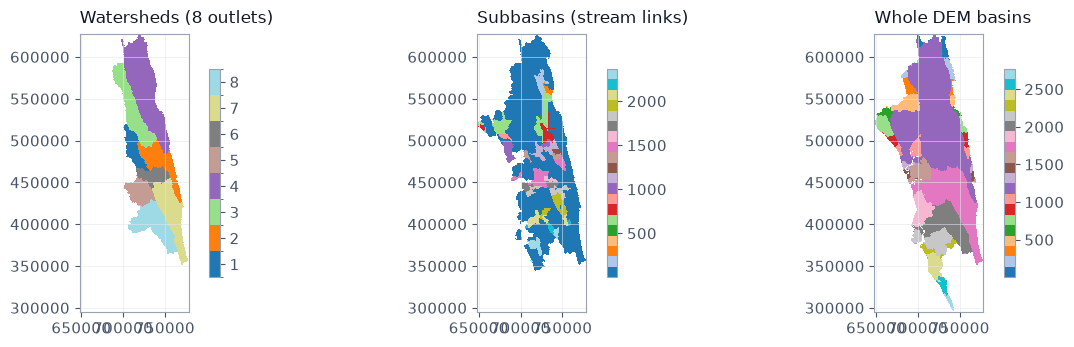

In [9]:
# Place pour points at high-accumulation stream cells (auto outlets).
with open_raster_data(fa_cells) as ds:
    fa2 = np.asarray(ds.read(bands=1), dtype=np.float64)  # D8 accumulation array
    nd = ds.get_band(1).nodata  # nodata flag
    gt = ds.geotransform  # origin and pixel size for map coords
if nd is not None:
    fa2 = np.where(fa2 == nd, np.nan, fa2)  # mask nodata

stream_mask = np.isfinite(st) & (st > 0)  # True on channel cells
# Pick a few local FA maxima along streams as outlets.
fa_stream = np.where(stream_mask, fa2, np.nan)  # FA only on streams
# Sample top cells, then keep spatially separated outlets.
flat_idx = np.argsort(-np.nan_to_num(fa_stream, nan=-np.inf), axis=None)  # high FA first
outlets = []  # list of (x, y) map coordinates
chosen = []  # list of (row, col) already accepted
rows, cols = fa_stream.shape  # array dimensions
for idx in flat_idx[:2000]:  # scan the top FA candidates
    r, c = divmod(int(idx), cols)  # convert flat index to row/col
    if not np.isfinite(fa_stream[r, c]):  # skip non-stream / nodata
        continue
    # Keep outlets ~20 km apart on the full mosaic (80 cells x 250 m).
    if any(abs(r - rr) + abs(c - cc) < 80 for rr, cc in chosen):
        continue  # too close to an existing outlet
    x = gt[0] + (c + 0.5) * gt[1]  # map X of cell centre
    y = gt[3] + (r + 0.5) * gt[5]  # map Y of cell centre
    outlets.append((x, y))  # accept this outlet
    chosen.append((r, c))  # remember its pixel location
    if len(outlets) >= 8:  # stop after eight outlets
        break

print(f"Candidate outlets (map coords): {len(outlets)}")  # how many outlets we kept
for i, (x, y) in enumerate(outlets, 1):
    print(f"  {i}: ({x:.1f}, {y:.1f})")  # print each outlet coordinate

snapped = snap_pour_points(outlets, streams, snap_distance=5000.0)  # snap onto streams within 5 km
print("Snapped:", snapped)  # confirm snapped coordinates

ws = OUT / "watersheds.tif"  # watersheds for the snapped outlets
watershed(d8p, snapped, ws, overwrite=True)  # delineate pour-point watersheds

sub = OUT / "subbasins.tif"  # subbasins per stream link
subbasins(d8p, streams, sub, overwrite=True)  # one subbasin per link

whole = OUT / "basins.tif"  # whole-DEM basin IDs
basins(d8p, whole, overwrite=True)  # basins draining to the DEM edge

# Side-by-side watershed / subbasin / whole-basin maps.
plot_rasters(
    [ws, sub, whole],  # basin rasters
    titles=[
        f"Watersheds ({len(snapped)} outlets)",  # pour-point watersheds
        "Subbasins (stream links)",  # link-based subbasins
        "Whole DEM basins",  # edge-draining basins
    ],
    ncols=3,  # three columns
    cmap="tab20",  # categorical colormap
    show=False,  # defer display
)
plt.show()  # render the basin maps


## Terrain hydrologic indices

### Elevation above stream (HAND-style)

Vertical height of each cell above the stream cell it drains to along the D8
path:

$$
\mathrm{EAS}_i = z_i - z_{s(i)}
$$

where $s(i)$ is the first stream cell downstream of $i$. Values near 0-2 m are
often candidate floodplain / valley-bottom cells.

### Downslope distance to stream

Path length following the flow network:

$$
D_i = \sum_{k \in \mathrm{path}(i \rightarrow s(i))} d_k
$$

with $d_k = \Delta x$ (cardinal) or $\sqrt{2}\,\Delta x$ (diagonal).
Alternatively, set `vertical=True` to return drop $z_i - z_{s(i)}$.


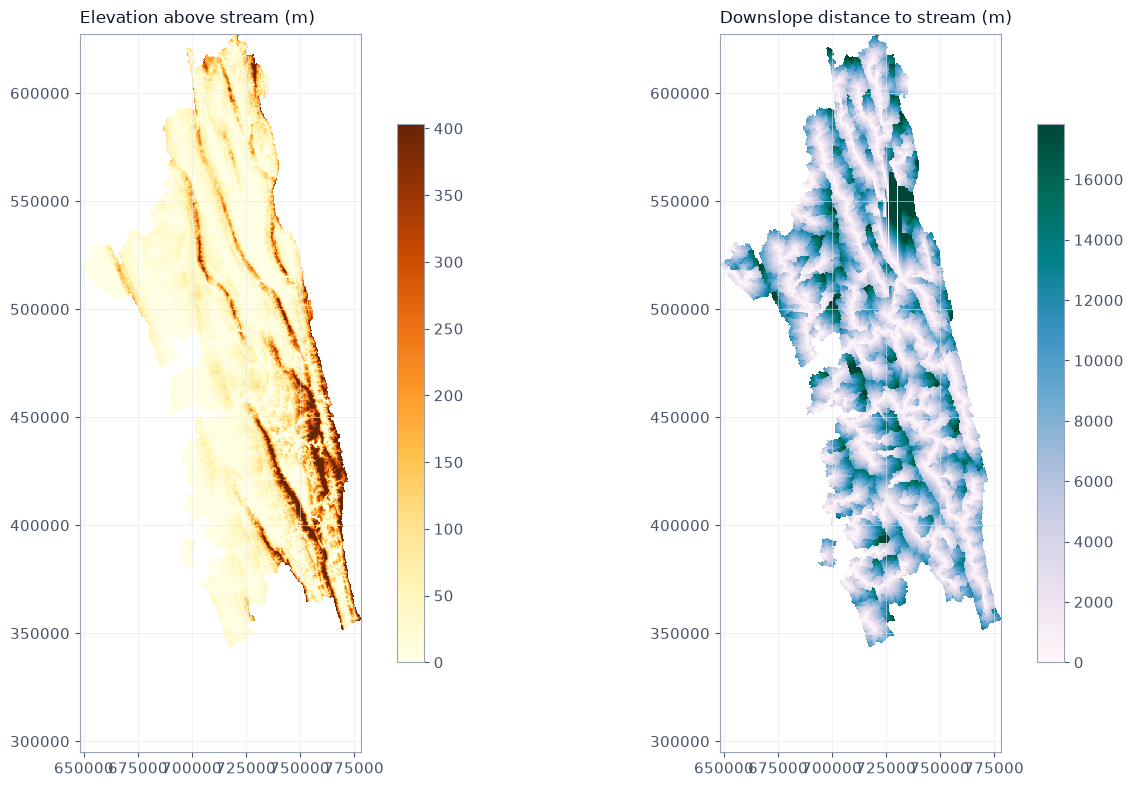

In [10]:
# Compute HAND-style elevation above stream and downslope distance to stream.
eas = OUT / "elevation_above_stream.tif"  # height above nearest stream (m)
dds = OUT / "distance_to_stream.tif"  # along-flow distance to stream (m)

elevation_above_stream(filled, streams, d8p, eas, overwrite=True)  # vertical height above channel
downslope_distance_to_stream(streams, d8p, dds, overwrite=True)  # flow-path distance to channel

# Side-by-side HAND and distance-to-stream maps.
fig, axes = plt.subplots(1, 2, figsize=(14, 8))  # two-panel figure
plot_raster(
    eas, ax=axes[0], title="Elevation above stream (m)", cmap="YlOrBr", robust=True, show=False
)  # left: HAND
plot_raster(
    dds, ax=axes[1], title="Downslope distance to stream (m)", cmap="PuBuGn", robust=True, show=False
)  # right: distance
plt.tight_layout()  # reduce unused whitespace
plt.show()  # render both panels


## Advanced analyses

### Stochastic depression analysis

Real DEMs have vertical uncertainty $\sigma$. A depression that appears once may
vanish under a different noise realisation. Monte Carlo perturbation:

$$
z^{(m)} = z + \varepsilon^{(m)},\quad
\varepsilon^{(m)} \sim \mathcal{N}(0, \sigma^2)
$$

Fill each realisation and record the fraction of iterations where cell $i$ was
raised:

$$
P(\text{depression})_i = \frac{1}{M}\sum_{m=1}^{M}
\mathbf{1}\!\left[z_i^{(m,\text{filled})} > z_i^{(m)}\right]
$$

Cells with $P > 0.5$ are more likely real basins than noise artefacts
([Whitebox stochastic depression analysis](https://www.whiteboxgeo.com/manuals/api/python/spatial-hydrology.html)).

### Hydrologic connectivity

Binary (or probabilistic) indicator of whether a cell drains to the stream
network along D8 within an optional maximum path distance: a simple proxy for
runoff contribution and variable source areas.

### Impoundment size index

For each potential dam cell, estimate the upslope volume (m³) or area (m²)
impounded by a dam of given length / height: useful for small-reservoir
screening.


/tmp/geolattice-src-path/geolattice/spatial_analysis/surface_hydrology.py:1038: RuntimeWarning: All-NaN slice encountered
  crest = np.nanmax(sliding_window_view(pad_c, dam_w, axis=1), axis=-1)


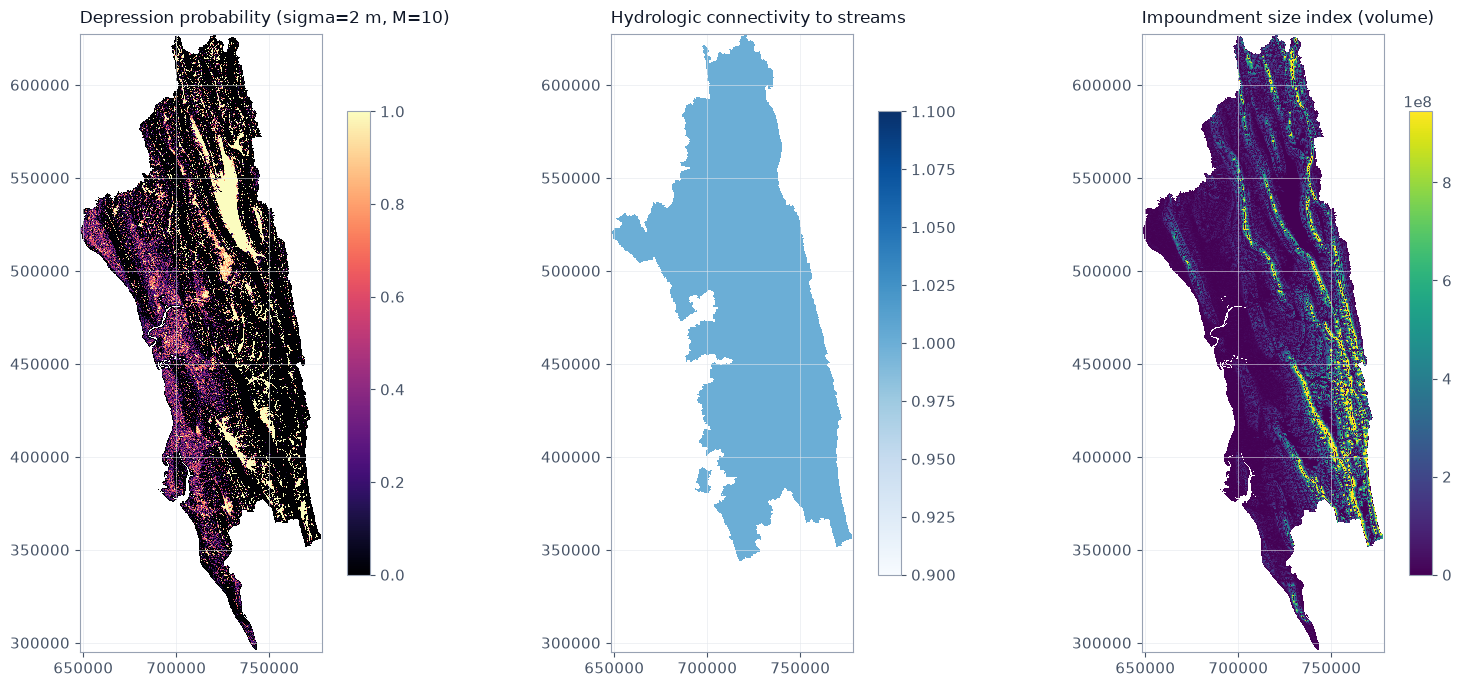

In [11]:
# Stochastic depression probability on the full DEM
# (fewer iterations than a research run so the notebook stays practical).
dep_prob = OUT / "depression_probability.tif"  # probability of being a depression
stochastic_depression_analysis(
    dem,  # raw DEM (uncertainty is on the observed surface)
    dep_prob,  # output probability raster
    n_iter=10,  # Monte Carlo iterations (small for a tutorial)
    error_magnitude=2.0,  # metres: illustrative for 250 m SRTM
    seed=7,  # reproducible random seed
    overwrite=True,  # replace any previous probability file
)

conn = OUT / "hydrologic_connectivity.tif"  # connectivity to streams
hydrologic_connectivity(filled, streams, conn, overwrite=True)  # upslope connection strength

imp = OUT / "impoundment_volume.tif"  # impoundment size index
impoundment_analysis(
    filled,  # conditioned DEM
    imp,  # output index raster
    dam_length=750.0,  # ~3 cells at 250 m
    out_type="volume",  # report a volume-style size index
    overwrite=True,  # replace any previous impoundment file
)

# Three-panel advanced hydrology products.
fig, axes = plt.subplots(1, 3, figsize=(16, 7))  # three-panel figure
plot_raster(
    dep_prob,  # depression probability
    ax=axes[0],
    title="Depression probability (sigma=2 m, M=10)",  # left title
    cmap="magma",
    robust=True,
    show=False,
)
plot_raster(
    conn,  # hydrologic connectivity
    ax=axes[1],
    title="Hydrologic connectivity to streams",  # middle title
    cmap="Blues",
    show=False,
)
plot_raster(
    imp,  # impoundment index
    ax=axes[2],
    title="Impoundment size index (volume)",  # right title
    cmap="viridis",
    robust=True,
    show=False,
)
plt.tight_layout()  # reduce unused whitespace
plt.show()  # render all three panels


## End-to-end pipeline (summary)

Hydrological analysis in this package follows the Whitebox preparation -> routing
-> network -> delineation progression:

1. **Condition** the DEM (`breach_depressions` + `fill_depressions`).
2. **Route** flow with the algorithm that matches the question (D8 for channels,
   Dinf for hillslope flux / TWI).
3. **Accumulate** flow and extract streams by thresholding.
4. **Delineate** watersheds / subbasins from outlets or channel junctions.
5. **Compute** terrain hydrologic indices (TWI, height above stream, distance).
6. **Advance** to probabilistic depression analysis, connectivity, or
   impoundment modelling when uncertainty or storage matters.

### Compact recipe

```python
from geolattice.spatial_analysis import (
    breach_depressions,
    fill_depressions,
    d8_pointer,
    d8_flow_accumulation,
    dinf_flow_accumulation,
    extract_streams,
    snap_pour_points,
    watershed,
    wetness_index,
)

breach_depressions("dem.tif", "breached.tif", fill_pits=True)
fill_depressions("breached.tif", "filled.tif")
d8_pointer("filled.tif", "d8.tif")
d8_flow_accumulation("filled.tif", "fa.tif", out_type="cells")
dinf_flow_accumulation("filled.tif", "sca.tif", out_type="sca")
extract_streams("fa.tif", "streams.tif", threshold=1000)
snap_pour_points([(x, y)], "streams.tif", "outlets.shp", snap_distance=5000)
watershed("d8.tif", "outlets.shp", "watersheds.tif")
wetness_index("filled.tif", "twi.tif", method="dinf")
```


In [12]:
# List every hydrology output file with its size on disk.
print("Hydrology outputs written to:")  # section header
for p in sorted(OUT.glob("*")):  # sorted listing of OUT contents
    if p.is_file():  # skip subdirectories if any
        print(f"  {p.name:40s}  {p.stat().st_size/1024:8.1f} KB")  # name and size in KB


Hydrology outputs written to:
  aoi_dem.tif                                  150.7 KB
  basins.tif                                  2710.9 KB
  d8_flow_accum_cells.tif                     2710.9 KB
  d8_pointer.tif                              2710.9 KB
  dem_breached.tif                            2710.9 KB
  dem_filled.tif                              2710.9 KB
  depression_probability.tif                  2710.9 KB
  dinf_pointer.tif                            2710.9 KB
  dinf_sca.tif                                2710.9 KB
  distance_to_stream.tif                      2710.9 KB
  elevation_above_stream.tif                  2710.9 KB
  fd8_weights.tif                            21646.1 KB
  hillshade.tif                                677.2 KB
  hydrologic_connectivity.tif                 2710.9 KB
  impoundment_volume.tif                      2710.9 KB
  rho8_pointer.tif                            2710.9 KB
  stream_links.tif                            2710.9 KB
  streams.tif     

## Further reading

1. [Whitebox Workflows: Spatial Hydrology](https://www.whiteboxgeo.com/manuals/api/python/spatial-hydrology.html)
   (DEM conditioning, D8 / Dinf, SCA, TWI, streams, watersheds, advanced tools)
2. [WhiteboxTools hydrology tool list](https://www.whiteboxgeo.com/manual/wbt_book/available_tools/hydrological_analysis.html)
3. Tarboton (1997): D-infinity flow direction
4. O'Callaghan & Mark (1984): D8
5. Beven & Kirkby / Quinn et al.: topographic wetness index
6. Project R notes: `R_Code/surface-hydrological-anlysis-whitbox-r.qmd`
7. Module source: `geolattice/spatial_analysis/surface_hydrology.py`
